In [1]:
# 1. Install the live streaming library
!pip install -q websockets

import asyncio
import json
import sqlite3
import time
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import websockets

DB_FILE = 'market_data.db'
STREAM_URL = 'wss://stream.binance.com:9443/ws/btcusdt@trade'

# 2. Setup Database
conn = sqlite3.connect(DB_FILE)
conn.execute('DROP TABLE IF EXISTS ticks')
conn.execute('CREATE TABLE ticks (timestamp REAL, price REAL, quantity REAL)')
conn.commit()
conn.close()

# 3. Stream Live Bitcoin Trades for 3 Minutes (180 seconds)
async def run_engine(duration_seconds=180):
    print(f"Connected to Binance! Capturing live Bitcoin trades for {duration_seconds} seconds...")
    start_time = time.time()

    async with websockets.connect(STREAM_URL) as ws:
        conn = sqlite3.connect(DB_FILE)
        last_print = 0

        while time.time() - start_time < duration_seconds:
            msg = json.loads(await ws.recv())
            ts = msg['T'] / 1000.0
            price = float(msg['p'])
            qty = float(msg['q'])

            conn.execute('INSERT INTO ticks VALUES (?, ?, ?)', (ts, price, qty))

            # Print a live update every 10 seconds
            if time.time() - last_print >= 10:
                conn.commit()
                df = pd.read_sql_query('SELECT * FROM ticks', conn)
                df['dt'] = pd.to_datetime(df['timestamp'], unit='s', utc=True)
                ohlc = df.set_index('dt')['price'].resample('1min').ohlc().dropna()

                if len(ohlc) >= 2:
                    log_rets = np.log(ohlc['close'] / ohlc['close'].shift(1)).dropna()
                    rv = np.sqrt(np.sum(log_rets**2) * (525600 / len(log_rets)))
                    print(f"[{datetime.now(timezone.utc).strftime('%H:%M:%S')} UTC] Ticks Captured: {len(df)} | 1m Bars: {len(ohlc)} | BTC: ${price:,.2f} | Live Realised Vol: {rv:.2%}")
                else:
                    print(f"[{datetime.now(timezone.utc).strftime('%H:%M:%S')} UTC] Ticks Captured: {len(df)} | Building first 1-minute bar... | BTC: ${price:,.2f}")
                last_print = time.time()

        conn.commit()
        conn.close()
    print("\nDONE! Live data saved to market_data.db.")

await run_engine(duration_seconds=180)

Connected to Binance! Capturing live Bitcoin trades for 180 seconds...
[16:11:59 UTC] Ticks Captured: 1 | Building first 1-minute bar... | BTC: $60,070.00
[16:12:10 UTC] Ticks Captured: 1119 | 1m Bars: 2 | BTC: $60,060.01 | Live Realised Vol: 7.23%
[16:12:20 UTC] Ticks Captured: 1769 | 1m Bars: 2 | BTC: $60,080.01 | Live Realised Vol: 16.91%
[16:12:30 UTC] Ticks Captured: 3455 | 1m Bars: 2 | BTC: $60,026.28 | Live Realised Vol: 47.96%
[16:12:40 UTC] Ticks Captured: 3978 | 1m Bars: 2 | BTC: $60,054.29 | Live Realised Vol: 14.14%
[16:12:52 UTC] Ticks Captured: 4598 | 1m Bars: 2 | BTC: $60,024.23 | Live Realised Vol: 50.43%
[16:13:02 UTC] Ticks Captured: 5330 | 1m Bars: 3 | BTC: $60,018.09 | Live Realised Vol: 37.71%
[16:13:12 UTC] Ticks Captured: 5960 | 1m Bars: 3 | BTC: $60,054.91 | Live Realised Vol: 46.91%
[16:13:23 UTC] Ticks Captured: 6697 | 1m Bars: 3 | BTC: $60,076.56 | Live Realised Vol: 59.84%
[16:13:34 UTC] Ticks Captured: 7925 | 1m Bars: 3 | BTC: $60,054.93 | Live Realised Vol

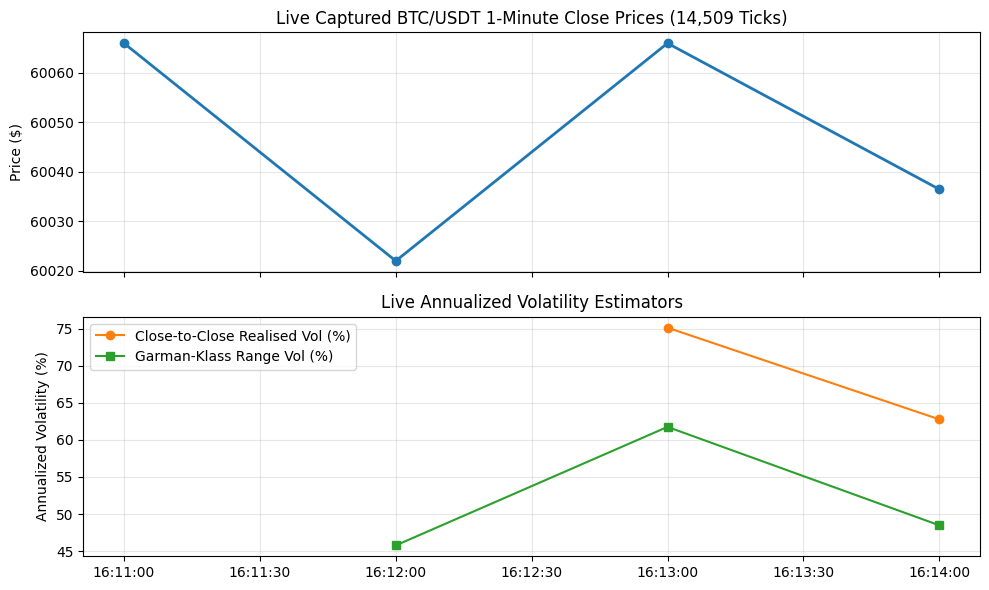

In [2]:
# Load your captured live data and build the proof chart
conn = sqlite3.connect('market_data.db')
df = pd.read_sql_query('SELECT * FROM ticks', conn)
conn.close()

df['dt'] = pd.to_datetime(df['timestamp'], unit='s', utc=True)
ohlc = df.set_index('dt')['price'].resample('1min').ohlc().dropna()

# Calculate Realised Volatility and Garman-Klass Range Volatility
log_rets = np.log(ohlc['close'] / ohlc['close'].shift(1))
rolling_rv = log_rets.rolling(2).std() * np.sqrt(525600)

hl = np.log(ohlc['high'] / ohlc['low']) ** 2
co = np.log(ohlc['close'] / ohlc['open']) ** 2
gk_var = 0.5 * hl - (2 * np.log(2) - 1) * co
rolling_gk = np.sqrt(gk_var.rolling(2).mean() * 525600)

# Draw and save the chart
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax1.plot(ohlc.index, ohlc['close'], color='#1f77b4', marker='o', linewidth=2)
ax1.set_title(f'Live Captured BTC/USDT 1-Minute Close Prices ({len(df):,} Ticks)')
ax1.set_ylabel('Price ($)')
ax1.grid(True, alpha=0.3)

ax2.plot(rolling_rv.index, rolling_rv * 100, label='Close-to-Close Realised Vol (%)', marker='o', color='#ff7f0e')
ax2.plot(rolling_gk.index, rolling_gk * 100, label='Garman-Klass Range Vol (%)', marker='s', color='#2ca02c')
ax2.set_title('Live Annualized Volatility Estimators')
ax2.set_ylabel('Annualized Volatility (%)')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('volatility_proof.png', dpi=150)
plt.show()